# Extreme class imbalance with GPU tree models
Notebook version of `imbalance_gpu_pipeline.py` (kernel: `causal-gpu`). Strict GPU: any model that fails its GPU probe (e.g. LightGBM here) is excluded, never run on CPU.

Set `QUICK = True` in the *Run* cell for a fast smoke test.

In [1]:
"""
Extreme class-imbalance pipeline with STRICTLY GPU-accelerated tree models.

Target environment : conda env `causal-gpu`
    C:\\Users\\RamaKrishna\\anaconda3\\envs\\causal-gpu\\python.exe imbalance_gpu_pipeline.py
Extra packages needed in that env: imbalanced-learn, optuna, catboost
    (see requirements.txt). A model whose library or GPU build is missing is
    EXCLUDED from the run (never silently downgraded to CPU).

Stages
------
 1. Setup        : output dirs, seeds, GPU verification + per-model GPU probe
 2. Data / EDA   : synthetic data, stratified 70/15/15 split, EDA plots
 3. Features     : leak-free FeatureEngineer (fit on train only)
 4. Modeling     : Optuna (Stratified K-Fold, objective = PR-AUC) for each GPU model
 5. Evaluation   : validation-tuned F-beta threshold, metrics table, comparison plots
"""
import functools
import itertools
import json
import os
import random
import shutil
import subprocess
import sys
import time
import warnings
from dataclasses import dataclass, field
from pathlib import Path
from typing import Callable, Dict, List, Optional

import matplotlib

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import joblib
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.covariance import LedoitWolf
from sklearn.datasets import make_classification
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score, confusion_matrix, f1_score, fbeta_score,
    matthews_corrcoef, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)

# ---------------------------------------------------------------------------
# Optional / required third-party imports. Missing OPTIONAL libs only remove the
# model that needs them; Optuna and XGBoost are required.
# ---------------------------------------------------------------------------
try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError:  # pragma: no cover
    sys.exit("optuna is required: pip install optuna  (in the causal-gpu env)")

try:
    import xgboost as xgb
except ImportError:  # pragma: no cover
    sys.exit("xgboost is required.")

try:
    import lightgbm as lgb
except ImportError:
    lgb = None
try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None
try:
    from imblearn.combine import SMOTETomek
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.under_sampling import RandomUnderSampler
except ImportError:
    ImbPipeline = None

C:\Users\RamaKrishna\anaconda3\envs\causal-gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. SETUP: config, directories, seeds, timing, GPU verification

In [2]:
# =============================================================================
# 1. SETUP: config, directories, seeds, timing, GPU verification
# =============================================================================
@dataclass
class Config:
    seed: int = 42
    n_rows: int = 100_000
    n_features: int = 30
    pos_weight: float = 0.005          # minority share -> 0.5 % positives
    val_size: float = 0.15
    test_size: float = 0.15
    cv_folds: int = 3
    n_trials: int = 15                 # Optuna trials per model
    n_trials_resample: int = 6         # SMOTETomek is CPU-heavy -> fewer trials
    max_estimators: int = 600
    beta: float = 2.0                  # F2: recall counts 2x more than precision
    data_path: Optional[str] = None    # CSV / Parquet with a `target` column
    out_dir: Path = Path("outputs")
    dpi: int = 300

    @property
    def data_plots(self) -> Path: return self.out_dir / "data_plots"
    @property
    def eval_plots(self) -> Path: return self.out_dir / "eval_plots"
    @property
    def models_dir(self) -> Path: return self.out_dir / "saved_models"


def timed(stage: str):
    """Decorator: print a banner + elapsed wall time for each pipeline stage."""
    def deco(fn):
        @functools.wraps(fn)
        def wrapper(*a, **k):
            print(f"\n{'=' * 78}\n[START] {stage}")
            t0 = time.perf_counter()
            out = fn(*a, **k)
            print(f"[DONE ] {stage}  ({time.perf_counter() - t0:.1f}s)")
            return out
        return wrapper
    return deco


def setup_dirs(cfg: Config) -> None:
    for d in (cfg.data_plots, cfg.eval_plots, cfg.models_dir):
        d.mkdir(parents=True, exist_ok=True)


def set_seed(seed: int) -> None:
    """Seed Python, NumPy and hash randomisation. Each ML library receives the
    same seed explicitly through its `random_state`/`seed` parameter, so runs
    are reproducible (GPU histogram kernels can still differ by float noise)."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


def nvidia_smi_info() -> Optional[str]:
    exe = shutil.which("nvidia-smi")
    if not exe:
        return None
    try:
        out = subprocess.run(
            [exe, "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
            capture_output=True, text=True, timeout=15)
        return out.stdout.strip() or None
    except Exception:
        return None


def _tiny_data(n=400, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 6))
    y = np.zeros(n, dtype=int)
    y[: n // 10] = 1
    X[y == 1] += 1.0
    return X, y

## 4a. MODEL REGISTRY  (defined early because GPU probing happens at startup)

In [3]:
# =============================================================================
# 4a. MODEL REGISTRY  (defined early because GPU probing happens at startup)
#
# Each ModelSpec bundles: a GPU probe, an Optuna search space, an estimator
# factory, a saver and a feature-importance getter. Imbalance handling lives in
# the search space (class weights, max_delta_step, min_child_samples, sampler).
# =============================================================================
@dataclass
class ModelSpec:
    name: str
    probe: Callable[[], None]
    suggest: Callable
    build: Callable
    save: Callable
    importance: Callable
    trials_attr: str = "n_trials"


def _xgb_common(p, seed):
    return dict(
        tree_method="hist", device="cuda",          # strict GPU
        max_delta_step=1,                           # caps leaf-weight steps: with ~0.5% positives a
                                                    # leaf's Hessian is tiny and Newton steps explode;
                                                    # this keeps logistic updates stable.
        n_estimators=p["n_estimators"], learning_rate=p["learning_rate"],
        max_depth=p["max_depth"], min_child_weight=p["min_child_weight"],
        subsample=p["subsample"], colsample_bytree=p["colsample_bytree"],
        reg_lambda=p["reg_lambda"], gamma=p["gamma"],
        objective="binary:logistic", eval_metric="aucpr",
        random_state=seed, n_jobs=1, verbosity=0,
    )


def _xgb_space(trial, ratio, cfg):
    return dict(
        n_estimators=trial.suggest_int("n_estimators", 100, cfg.max_estimators),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 9),
        min_child_weight=trial.suggest_float("min_child_weight", 0.5, 20, log=True),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 50, log=True),
        gamma=trial.suggest_float("gamma", 0.0, 5.0),
    )


def _make_xgb_spec(cfg) -> ModelSpec:
    def probe():
        X, y = _tiny_data()
        xgb.XGBClassifier(**_xgb_common(dict(n_estimators=2, learning_rate=.3, max_depth=2,
                                             min_child_weight=1, subsample=1, colsample_bytree=1,
                                             reg_lambda=1, gamma=0), 0)).fit(X, y)

    def suggest(trial, ratio):
        p = _xgb_space(trial, ratio, cfg)
        # scale_pos_weight searched on a log scale from 1 (no reweighting) to ~ratio:
        # full neg/pos weighting often over-predicts positives; the optimum is usually
        # between sqrt(ratio) and ratio, so we let TPE find it on PR-AUC.
        p["scale_pos_weight"] = trial.suggest_float("scale_pos_weight", 1.0, ratio * 1.5, log=True)
        return p

    def build(p, seed, ratio):
        return xgb.XGBClassifier(scale_pos_weight=p["scale_pos_weight"], **_xgb_common(p, seed))

    return ModelSpec("XGBoost_GPU", probe, suggest, build,
                     save=lambda m, d: _save_xgb(m, d / "xgboost_gpu.json"),
                     importance=lambda m: m.feature_importances_)


def _make_lgb_spec(cfg) -> Optional[ModelSpec]:
    if lgb is None:
        return None

    def probe():
        X, y = _tiny_data()
        lgb.LGBMClassifier(device="gpu", n_estimators=2, verbose=-1).fit(X, y)

    def suggest(trial, ratio):
        p = dict(
            n_estimators=trial.suggest_int("n_estimators", 100, cfg.max_estimators),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            num_leaves=trial.suggest_int("num_leaves", 8, 128, log=True),
            # Large min_child_samples stops the model carving leaves around 1-2 positives
            # (memorisation), the classic failure mode on tiny minority classes.
            min_child_samples=trial.suggest_int("min_child_samples", 10, 300, log=True),
            subsample=trial.suggest_float("subsample", 0.6, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 50, log=True),
        )
        p["weighting"] = trial.suggest_categorical("weighting", ["is_unbalance", "scale_pos_weight"])
        if p["weighting"] == "scale_pos_weight":
            p["scale_pos_weight"] = trial.suggest_float("scale_pos_weight", 1.0, ratio * 1.5, log=True)
        return p

    def build(p, seed, ratio):
        kw = dict(device="gpu", objective="binary", n_estimators=p["n_estimators"],
                  learning_rate=p["learning_rate"], num_leaves=p["num_leaves"],
                  min_child_samples=p["min_child_samples"], subsample=p["subsample"],
                  subsample_freq=1, colsample_bytree=p["colsample_bytree"],
                  reg_lambda=p["reg_lambda"], random_state=seed, verbose=-1, n_jobs=1)
        # is_unbalance and scale_pos_weight are mutually exclusive in LightGBM.
        if p["weighting"] == "is_unbalance":
            kw["is_unbalance"] = True
        else:
            kw["scale_pos_weight"] = p["scale_pos_weight"]
        return lgb.LGBMClassifier(**kw)

    return ModelSpec("LightGBM_GPU", probe, suggest, build,
                     save=lambda m, d: _save_lgb(m, d / "lightgbm_gpu.txt"),
                     importance=lambda m: m.booster_.feature_importance("gain"))


def _make_cat_spec(cfg) -> Optional[ModelSpec]:
    if CatBoostClassifier is None:
        return None

    def probe():
        X, y = _tiny_data()
        CatBoostClassifier(task_type="GPU", iterations=2, verbose=0, allow_writing_files=False).fit(X, y)

    def suggest(trial, ratio):
        return dict(
            iterations=trial.suggest_int("iterations", 100, cfg.max_estimators),
            learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
            depth=trial.suggest_int("depth", 4, 9),
            l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 30.0, log=True),
            # Balanced = full inverse-frequency weights, SqrtBalanced = softer (sqrt) version.
            auto_class_weights=trial.suggest_categorical("auto_class_weights", ["Balanced", "SqrtBalanced"]),
            border_count=trial.suggest_categorical("border_count", [64, 128, 254]),
        )

    def build(p, seed, ratio):
        return CatBoostClassifier(task_type="GPU", loss_function="Logloss", eval_metric="Logloss",  # PRAUC has no GPU kernel; tuning objective is PR-AUC anyway
                                  random_seed=seed, verbose=0, allow_writing_files=False, **p)

    return ModelSpec("CatBoost_GPU", probe, suggest, build,
                     save=lambda m, d: _save_cat(m, d / "catboost_gpu.cbm"),
                     importance=lambda m: m.get_feature_importance())


def _make_resample_spec(cfg, xgb_spec: ModelSpec) -> Optional[ModelSpec]:
    if ImbPipeline is None:
        return None

    def sampler(p, seed):
        if p["sampler"] == "undersample":
            return RandomUnderSampler(sampling_strategy=p["sampling_ratio"], random_state=seed)
        # SMOTETomek: SMOTE synthesises minority points, Tomek-link removal then cleans the
        # overlapping boundary. sampling_ratio = target minority/majority after resampling.
        return SMOTETomek(sampling_strategy=p["sampling_ratio"], random_state=seed, n_jobs=1)

    def suggest(trial, ratio):
        p = _xgb_space(trial, ratio, cfg)
        p["sampler"] = trial.suggest_categorical("sampler", ["undersample", "smotetomek"])
        p["sampling_ratio"] = trial.suggest_float("sampling_ratio", 0.02, 0.5, log=True)
        return p

    def build(p, seed, ratio):
        # No class weighting here: imbalance is handled purely at the DATA level so the
        # comparison against the cost-sensitive models above is clean. The imblearn
        # Pipeline applies the sampler in fit() only, never at predict() time.
        return ImbPipeline([("sampler", sampler(p, seed)),
                            ("xgb", xgb.XGBClassifier(scale_pos_weight=1.0, **_xgb_common(p, seed)))])

    return ModelSpec("Resample+XGB_GPU", xgb_spec.probe, suggest, build,
                     save=lambda m, d: _save_joblib(m, d / "resample_xgb_gpu_pipeline.joblib"),
                     importance=lambda m: m.named_steps["xgb"].feature_importances_,
                     trials_attr="n_trials_resample")


def _save_xgb(m, path): m.save_model(str(path)); return path
def _save_lgb(m, path): m.booster_.save_model(str(path)); return path
def _save_cat(m, path): m.save_model(str(path)); return path
def _save_joblib(m, path): joblib.dump(m, path); return path


@timed("GPU verification & model probing")
def probe_gpu_models(cfg: Config) -> List[ModelSpec]:
    """Return only the models that can really train on the GPU.

    Strict-GPU policy: a model whose GPU probe fit fails (library missing, CPU-only
    build, no CUDA) is EXCLUDED with a warning. Nothing falls back to CPU."""
    info = nvidia_smi_info()
    if info is None:
        print("[WARN] nvidia-smi not found / no NVIDIA GPU detected.")
    else:
        print(f"[GPU ] {info}")

    xgb_spec = _make_xgb_spec(cfg)
    candidates = [xgb_spec, _make_lgb_spec(cfg), _make_cat_spec(cfg), _make_resample_spec(cfg, xgb_spec)]
    names = ["XGBoost_GPU", "LightGBM_GPU", "CatBoost_GPU", "Resample+XGB_GPU"]
    ok: List[ModelSpec] = []
    for nm, spec in zip(names, candidates):
        if spec is None:
            print(f"[SKIP] {nm}: required library not installed -> excluded")
            continue
        try:
            spec.probe()
            print(f"[ OK ] {nm}: GPU probe passed")
            ok.append(spec)
        except Exception as e:  # noqa: BLE001
            print(f"[SKIP] {nm}: GPU unavailable -> excluded ({str(e).splitlines()[0][:110]})")
    if not ok:
        sys.exit("[FATAL] No model could run on the GPU. Aborting (CPU fallback is disabled).")
    return ok

## 2. DATA LEVEL: loading, stratified split, EDA

In [4]:
# =============================================================================
# 2. DATA LEVEL: loading, stratified split, EDA
# =============================================================================
@timed("Data loading")
def load_data(cfg: Config) -> pd.DataFrame:
    # ---- PLUG IN YOUR OWN DATA HERE ----------------------------------------
    # if cfg.data_path:
    #     df = pd.read_parquet(cfg.data_path)     # or pd.read_csv(cfg.data_path)
    #     # required: a binary column named "target"; all other columns numeric
    #     return df
    # -------------------------------------------------------------------------
    if cfg.data_path:
        p = Path(cfg.data_path)
        df = pd.read_parquet(p) if p.suffix == ".parquet" else pd.read_csv(p)
        assert "target" in df.columns, "custom data needs a binary 'target' column"
        return df

    X, y = make_classification(
        n_samples=cfg.n_rows, n_features=cfg.n_features, n_informative=8, n_redundant=4,
        n_repeated=0, n_clusters_per_class=2, weights=[1 - cfg.pos_weight, cfg.pos_weight],
        flip_y=0.001,        # a little label noise, as in real fraud / defect data
        class_sep=1.0, random_state=cfg.seed)
    df = pd.DataFrame(X, columns=[f"f{i}" for i in range(cfg.n_features)])
    # Sprinkle ~0.5% missing cells so the imputation step is exercised.
    rng = np.random.default_rng(cfg.seed)
    mask = rng.random(df.shape) < 0.005
    df = df.mask(mask)
    df["target"] = y
    print(f"rows={len(df):,}  positives={int(y.sum()):,} ({y.mean():.3%})")
    return df


@timed("Stratified train/val/test split")
def split_data(df: pd.DataFrame, cfg: Config):
    """Split FIRST, before any preprocessing/resampling, so nothing learned from
    validation/test rows can leak into training. `stratify=y` is essential: a
    plain random split of a 0.5% class can leave a split with almost no positives."""
    y = df["target"].to_numpy()
    X = df.drop(columns="target")
    X_tmp, X_te, y_tmp, y_te = train_test_split(
        X, y, test_size=cfg.test_size, stratify=y, random_state=cfg.seed)
    rel_val = cfg.val_size / (1 - cfg.test_size)
    X_tr, X_va, y_tr, y_va = train_test_split(
        X_tmp, y_tmp, test_size=rel_val, stratify=y_tmp, random_state=cfg.seed)
    for n, yy in (("train", y_tr), ("val", y_va), ("test", y_te)):
        print(f"{n:5s}: {len(yy):>7,} rows, {int(yy.sum()):>4} positives ({yy.mean():.3%})")
    return X_tr.reset_index(drop=True), X_va.reset_index(drop=True), X_te.reset_index(drop=True), y_tr, y_va, y_te


@timed("EDA plots")
def eda_plots(X_tr: pd.DataFrame, y_tr: np.ndarray, cfg: Config) -> None:
    """EDA on TRAIN ONLY: looking at val/test would be a (mild) form of leakage."""
    # --- class distribution: linear scale hides the minority, log scale reveals it ---
    counts = pd.Series(y_tr).value_counts().sort_index()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, log in zip(axes, (False, True)):
        bars = ax.bar(["Majority (0)", "Minority (1)"], counts.values, color=["#4C72B0", "#C44E52"])
        if log:
            ax.set_yscale("log")
        ax.set_title("Class counts (log scale)" if log else "Class counts (raw)")
        ax.set_ylabel("count")
        for b, c in zip(bars, counts.values):
            ax.text(b.get_x() + b.get_width() / 2, c, f"{c:,}", ha="center", va="bottom")
    fig.tight_layout()
    fig.savefig(cfg.data_plots / "class_distribution.png", dpi=cfg.dpi)
    plt.show()

    # --- correlation of features with target (point-biserial = Pearson with 0/1) ---
    # NaNs are ignored pairwise by DataFrame.corr.
    d = X_tr.copy()
    d["target"] = y_tr
    corr_t = d.corr()["target"].drop("target")
    top = corr_t.abs().sort_values(ascending=False).head(15).index.tolist()
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(d[top + ["target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
    ax.set_title("Correlation heatmap: top-15 features vs target")
    fig.tight_layout()
    fig.savefig(cfg.data_plots / "correlation_heatmap.png", dpi=cfg.dpi)
    plt.show()

    # --- distributions of the 4 most predictive features, per class ---
    # KDEs are density-normalised per class, so the 200x size gap does not hide shape shifts.
    top4 = top[:4]
    fig, axes = plt.subplots(2, 4, figsize=(18, 7))
    for i, f in enumerate(top4):
        sns.kdeplot(data=d, x=f, hue="target", common_norm=False, fill=True,
                    palette=["#4C72B0", "#C44E52"], ax=axes[0, i])
        axes[0, i].set_title(f"{f} (|corr|={abs(corr_t[f]):.2f})")
        sns.boxplot(data=d, x="target", y=f, palette=["#4C72B0", "#C44E52"],
                    hue="target", legend=False, ax=axes[1, i])
    fig.tight_layout()
    fig.savefig(cfg.data_plots / "top4_feature_distributions.png", dpi=cfg.dpi)
    plt.show()
    print(f"saved 3 plots to {cfg.data_plots}")

## 3. FEATURE ENGINEERING LEVEL (leak-free transformer)

In [5]:
# =============================================================================
# 3. FEATURE ENGINEERING LEVEL (leak-free transformer)
# =============================================================================
class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Fitted ONLY on training data. Produces:
      * median-imputed, standardised raw features
      * pairwise product / difference interactions of the most informative features
        (minority points often sit in a small joint region trees need many splits to carve)
      * frequency + smoothed target encoding of quantile bins of top features
      * anomaly scores: IsolationForest + Mahalanobis distance (rare class ~ outlier)
    Target encoding on the training matrix is computed OUT-OF-FOLD (fit_transform),
    otherwise each row would see its own label and the model would overfit to it.
    """

    def __init__(self, n_top=6, n_bins=10, smoothing=20.0, n_oof=5, seed=42):
        self.n_top, self.n_bins, self.smoothing, self.n_oof, self.seed = n_top, n_bins, smoothing, n_oof, seed

    # ---- helpers ----
    def _prep(self, X):
        X = pd.DataFrame(X).reindex(columns=self.raw_cols_)
        return self.scaler_.transform(self.imputer_.transform(X))

    def _bins(self, Z):
        return np.column_stack([np.digitize(Z[:, j], self.edges_[j]) for j in self.top_idx_])

    def _te_stats(self, B, y):
        """Per-bin smoothed target rate. Smoothing shrinks rates of sparse bins toward the
        global prior: with ~0.5% positives a bin with 1 positive would otherwise get a wildly
        noisy rate. rate = (pos + prior*m) / (n + m)."""
        maps = []
        for k in range(B.shape[1]):
            nb = len(self.edges_[self.top_idx_[k]]) + 1
            n = np.bincount(B[:, k], minlength=nb)
            pos = np.bincount(B[:, k], weights=y, minlength=nb)
            maps.append((pos + self.prior_ * self.smoothing) / (n + self.smoothing))
        return maps

    def _apply_te(self, B, maps):
        return np.column_stack([maps[k][B[:, k]] for k in range(B.shape[1])])

    def _assemble(self, Z, B, te):
        inter, names_i = [], []
        for a, b in itertools.combinations(self.top_idx_, 2):
            inter += [Z[:, a] * Z[:, b], Z[:, a] - Z[:, b]]
        inter = np.column_stack(inter)
        freq = np.column_stack([self.freq_[k][B[:, k]] for k in range(B.shape[1])])
        iso = -self.iso_.score_samples(Z)                      # higher = more anomalous
        maha = np.sqrt(self.cov_.mahalanobis(Z))
        return np.column_stack([Z, inter, freq, te, iso, maha])

    # ---- sklearn API ----
    def fit(self, X, y):
        X = pd.DataFrame(X)
        y = np.asarray(y).astype(float)
        self.raw_cols_ = list(X.columns)
        self.imputer_ = SimpleImputer(strategy="median").fit(X)
        self.scaler_ = StandardScaler().fit(self.imputer_.transform(X))
        Z = self.scaler_.transform(self.imputer_.transform(X))

        # rank features by mutual information on a subsample that keeps all positives
        rng = np.random.default_rng(self.seed)
        pos = np.where(y == 1)[0]
        neg = rng.choice(np.where(y == 0)[0], size=min(20000, int((y == 0).sum())), replace=False)
        idx = np.concatenate([pos, neg])
        mi = mutual_info_classif(Z[idx], y[idx], random_state=self.seed)
        self.top_idx_ = np.argsort(mi)[::-1][: self.n_top]

        qs = np.linspace(0, 1, self.n_bins + 1)[1:-1]
        self.edges_ = {j: np.unique(np.quantile(Z[:, j], qs)) for j in self.top_idx_}
        self.prior_ = float(y.mean())
        B = self._bins(Z)
        self.freq_ = [np.bincount(B[:, k], minlength=len(self.edges_[j]) + 1) / len(B)
                      for k, j in enumerate(self.top_idx_)]
        self.te_maps_ = self._te_stats(B, y)
        self.iso_ = IsolationForest(n_estimators=200, random_state=self.seed, n_jobs=-1).fit(Z)
        self.cov_ = LedoitWolf().fit(Z)

        top_names = [self.raw_cols_[j] for j in self.top_idx_]
        pair_names = [f"{self.raw_cols_[a]}*{self.raw_cols_[b]}" if t == 0 else f"{self.raw_cols_[a]}-{self.raw_cols_[b]}"
                      for a, b in itertools.combinations(self.top_idx_, 2) for t in (0, 1)]
        self.names_ = (self.raw_cols_ + pair_names + [f"freq_{n}" for n in top_names]
                       + [f"te_{n}" for n in top_names] + ["iso_anomaly", "mahalanobis"])
        self._y_fit, self._Z_fit = y, Z    # needed by fit_transform only
        return self

    def transform(self, X):
        Z = self._prep(X)
        B = self._bins(Z)
        return self._assemble(Z, B, self._apply_te(B, self.te_maps_))

    def fit_transform(self, X, y=None, **kw):
        self.fit(X, y)
        Z, yv = self._Z_fit, self._y_fit
        B = self._bins(Z)
        te = np.zeros((len(Z), B.shape[1]))
        skf = StratifiedKFold(self.n_oof, shuffle=True, random_state=self.seed)
        for tr, ho in skf.split(Z, yv):                         # out-of-fold target encoding
            maps = self._te_stats(B[tr], yv[tr])
            te[ho] = self._apply_te(B[ho], maps)
        out = self._assemble(Z, B, te)
        del self._Z_fit, self._y_fit
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array(self.names_)


@timed("Feature engineering (fit on train only)")
def build_features(X_tr, y_tr, X_va, X_te, cfg: Config):
    fe = FeatureEngineer(seed=cfg.seed)
    A_tr = fe.fit_transform(X_tr, y_tr)
    A_va, A_te = fe.transform(X_va), fe.transform(X_te)
    print(f"features: {X_tr.shape[1]} raw -> {A_tr.shape[1]} engineered")
    joblib.dump(fe, cfg.models_dir / "feature_engineer.joblib")
    return fe, A_tr, A_va, A_te

## 4b. MODELING LEVEL: Optuna tuning on PR-AUC with Stratified K-Fold

In [6]:
# =============================================================================
# 4b. MODELING LEVEL: Optuna tuning on PR-AUC with Stratified K-Fold
# =============================================================================
def make_cv_folds(X_raw: pd.DataFrame, y: np.ndarray, cfg: Config):
    """Pre-compute fold matrices. The FeatureEngineer is re-fitted on each fold's
    TRAINING part only, so target encodings / anomaly scores never see the fold's
    held-out rows (leak-free CV). Folds are reused across every model and trial."""
    skf = StratifiedKFold(cfg.cv_folds, shuffle=True, random_state=cfg.seed)
    folds = []
    for tr, ho in skf.split(X_raw, y):
        fe = FeatureEngineer(seed=cfg.seed)
        A_tr = fe.fit_transform(X_raw.iloc[tr], y[tr])
        folds.append((A_tr, y[tr], fe.transform(X_raw.iloc[ho]), y[ho]))
    return folds


def cv_pr_auc(spec: ModelSpec, params: dict, folds, seed: int, ratio: float) -> float:
    scores = []
    for A_tr, y_tr, A_ho, y_ho in folds:
        m = spec.build(params, seed, ratio)
        m.fit(A_tr, y_tr)                       # resampling (if any) happens inside fit only
        scores.append(average_precision_score(y_ho, m.predict_proba(A_ho)[:, 1]))
    return float(np.mean(scores))


@timed("Hyper-parameter tuning + final training")
def tune_and_train(specs, folds, A_tr, y_tr, ratio, cfg: Config):
    """Optimise PR-AUC (average precision), NOT accuracy/ROC-AUC: with 0.5% positives a
    constant 'negative' predictor has 99.5% accuracy and ROC-AUC is dominated by the
    huge true-negative pool, whereas PR-AUC only looks at how well positives are ranked."""
    trained: Dict[str, object] = {}
    best_params: Dict[str, dict] = {}
    for spec in specs:
        t0 = time.perf_counter()
        n_trials = getattr(cfg, spec.trials_attr)
        print(f"\n--- {spec.name}: {n_trials} Optuna trials ---")
        try:
            def objective(trial, spec=spec):
                return cv_pr_auc(spec, spec.suggest(trial, ratio), folds, cfg.seed, ratio)

            study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=cfg.seed))
            study.optimize(objective, n_trials=n_trials, catch=(Exception,))
            if not any(t.state.name == "COMPLETE" for t in study.trials):
                raise RuntimeError("every Optuna trial failed")
            print(f"best CV PR-AUC = {study.best_value:.4f}")
            params = study.best_trial.params
            # Re-materialise the full parameter dict (suggest() with a frozen trial replays values)
            frozen = optuna.trial.FixedTrial(params)
            full = spec.suggest(frozen, ratio)
            model = spec.build(full, cfg.seed, ratio)
            model.fit(A_tr, y_tr)
            trained[spec.name], best_params[spec.name] = model, {k: _jsonable(v) for k, v in full.items()}
            path = spec.save(model, cfg.models_dir)
            print(f"saved -> {path}  ({time.perf_counter() - t0:.1f}s)")
        except Exception as e:  # noqa: BLE001
            print(f"[WARN] {spec.name} failed and is excluded from evaluation: {e}")
    if not trained:
        sys.exit("[FATAL] no model trained successfully.")
    (cfg.models_dir / "best_params.json").write_text(json.dumps(best_params, indent=2))
    return trained


def _jsonable(v):
    return v.item() if isinstance(v, np.generic) else v

## 5. EVALUATION & THRESHOLD OPTIMISATION

In [7]:
# =============================================================================
# 5. EVALUATION & THRESHOLD OPTIMISATION
# =============================================================================
def tune_threshold(y_true, proba, beta: float):
    """Pick the probability cut-off that maximises F-beta on VALIDATION data.
    The default 0.5 is meaningless under extreme imbalance (calibrated scores for
    positives are rarely > 0.5, and class-weighted models are shifted the other way).
    beta=2 favours recall, appropriate when a missed positive costs more than a false alarm."""
    prec, rec, thr = precision_recall_curve(y_true, proba)
    prec, rec = prec[:-1], rec[:-1]                      # align with thr
    f = (1 + beta**2) * prec * rec / np.maximum(beta**2 * prec + rec, 1e-12)
    i = int(np.nanargmax(f))
    return float(thr[i]), float(f[i])


def metrics_at(y, proba, thr, beta):
    pred = (proba >= thr).astype(int)
    return {
        "PR-AUC": average_precision_score(y, proba),
        "ROC-AUC": roc_auc_score(y, proba),
        "F1": f1_score(y, pred, zero_division=0),
        "F2": fbeta_score(y, pred, beta=beta, zero_division=0),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "MCC": matthews_corrcoef(y, pred),
    }


@timed("Evaluation & threshold tuning")
def evaluate(trained, A_va, y_va, A_te, y_te, cfg: Config):
    rows, store = [], {}
    for name, m in trained.items():
        p_va, p_te = m.predict_proba(A_va)[:, 1], m.predict_proba(A_te)[:, 1]
        thr, f_val = tune_threshold(y_va, p_va, cfg.beta)       # threshold learned on val ONLY
        res = metrics_at(y_te, p_te, thr, cfg.beta)             # applied unchanged to test
        rows.append({"Model": name, "Threshold": thr, "Val F%g" % cfg.beta: f_val,
                     "Val PR-AUC": average_precision_score(y_va, p_va), **res})
        store[name] = dict(p_va=p_va, p_te=p_te, thr=thr)
    table = pd.DataFrame(rows).set_index("Model")
    print("\nTEST-SET RESULTS (threshold tuned on validation)")
    print(table.round(4).to_string())
    table.round(6).to_csv(cfg.out_dir / "metrics_summary.csv")
    # Winner = best VALIDATION PR-AUC (picking by test would leak the test set into selection)
    best = table["Val PR-AUC"].idxmax()
    print(f"\nBest model (by validation PR-AUC): {best}")
    return table, store, best


@timed("Evaluation plots")
def eval_plots(trained, store, table, best, fe, y_va, y_te, specs, cfg: Config):
    names = list(trained)
    cmap = plt.get_cmap("tab10")

    # --- combined PR curves (primary metric) ---
    fig, ax = plt.subplots(figsize=(8, 6))
    for i, n in enumerate(names):
        pr, rc, _ = precision_recall_curve(y_te, store[n]["p_te"])
        ax.plot(rc, pr, color=cmap(i), lw=2, label=f"{n} (AP={table.loc[n, 'PR-AUC']:.3f})")
    ax.axhline(y_te.mean(), color="gray", ls="--", label=f"No-skill ({y_te.mean():.3%})")
    ax.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curves (test)")
    ax.legend(); ax.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(cfg.eval_plots / "pr_curves.png", dpi=cfg.dpi); plt.show()

    # --- combined ROC curves ---
    fig, ax = plt.subplots(figsize=(8, 6))
    for i, n in enumerate(names):
        fpr, tpr, _ = roc_curve(y_te, store[n]["p_te"])
        ax.plot(fpr, tpr, color=cmap(i), lw=2, label=f"{n} (AUC={table.loc[n, 'ROC-AUC']:.3f})")
    ax.plot([0, 1], [0, 1], "k--", label="Chance")
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test)")
    ax.legend(); ax.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(cfg.eval_plots / "roc_curves.png", dpi=cfg.dpi); plt.show()

    # --- normalised confusion matrices at tuned thresholds ---
    fig, axes = plt.subplots(1, len(names), figsize=(4.6 * len(names), 4.2), squeeze=False)
    for ax, n in zip(axes[0], names):
        pred = (store[n]["p_te"] >= store[n]["thr"]).astype(int)
        cm = confusion_matrix(y_te, pred, normalize="true")   # row-normalised: shows recall per class
        sns.heatmap(cm, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                    xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
        ax.set_title(f"{n}\nthr={store[n]['thr']:.3f}")
    fig.tight_layout(); fig.savefig(cfg.eval_plots / "confusion_matrices.png", dpi=cfg.dpi); plt.show()

    # --- threshold vs precision / recall / F1 for the best model ---
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    grid = np.linspace(0.005, 0.995, 400)
    for ax, (lbl, y, p) in zip(axes, (("validation", y_va, store[best]["p_va"]), ("test", y_te, store[best]["p_te"]))):
        pr = [precision_score(y, p >= t, zero_division=0) for t in grid]
        rc = [recall_score(y, p >= t, zero_division=0) for t in grid]
        f1 = [f1_score(y, p >= t, zero_division=0) for t in grid]
        ax.plot(grid, pr, label="Precision"); ax.plot(grid, rc, label="Recall"); ax.plot(grid, f1, label="F1")
        ax.axvline(store[best]["thr"], color="k", ls="--", label=f"Tuned thr={store[best]['thr']:.3f}")
        ax.set(xlabel="Threshold", title=f"{best} - {lbl}"); ax.grid(alpha=.3); ax.legend()
    fig.tight_layout(); fig.savefig(cfg.eval_plots / "threshold_curve_best_model.png", dpi=cfg.dpi); plt.show()

    # --- top-20 feature importance of the winner ---
    spec = next(s for s in specs if s.name == best)
    imp = np.asarray(spec.importance(trained[best]), dtype=float)
    s = pd.Series(imp, index=fe.get_feature_names_out()).sort_values(ascending=False).head(20)[::-1]
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.barh(s.index, s.values, color="#4C72B0")
    ax.set(title=f"Top-20 feature importance - {best}", xlabel="importance")
    fig.tight_layout(); fig.savefig(cfg.eval_plots / "feature_importance.png", dpi=cfg.dpi); plt.show()
    print(f"saved 5 plots to {cfg.eval_plots}")

## Run the pipeline

In [8]:
QUICK = False   # True -> 30k rows, 2 trials per model

t_all = time.perf_counter()
cfg = Config()
if QUICK:
    cfg.n_rows, cfg.pos_weight, cfg.n_trials, cfg.n_trials_resample, cfg.max_estimators = 30_000, 0.01, 2, 2, 150
setup_dirs(cfg)
set_seed(cfg.seed)
print(f"python {sys.version.split()[0]} | {sys.executable} | xgboost {xgb.__version__}")
specs = probe_gpu_models(cfg)

python 3.12.16 | C:\Users\RamaKrishna\anaconda3\envs\causal-gpu\python.exe | xgboost 3.4.1

[START] GPU verification & model probing
[GPU ] NVIDIA GeForce RTX 3090, 24576 MiB, 610.60


[ OK ] XGBoost_GPU: GPU probe passed
[SKIP] LightGBM_GPU: GPU unavailable -> excluded (GPU Tree Learner was not enabled in this build.)


[ OK ] CatBoost_GPU: GPU probe passed
[ OK ] Resample+XGB_GPU: GPU probe passed
[DONE ] GPU verification & model probing  (1.2s)



[START] Data loading
rows=100,000  positives=542 (0.542%)
[DONE ] Data loading  (0.1s)

[START] Stratified train/val/test split


train:  69,999 rows,  380 positives (0.543%)


val  :  15,001 rows,   81 positives (0.540%)
test :  15,000 rows,   81 positives (0.540%)
[DONE ] Stratified train/val/test split  (0.1s)

[START] EDA plots


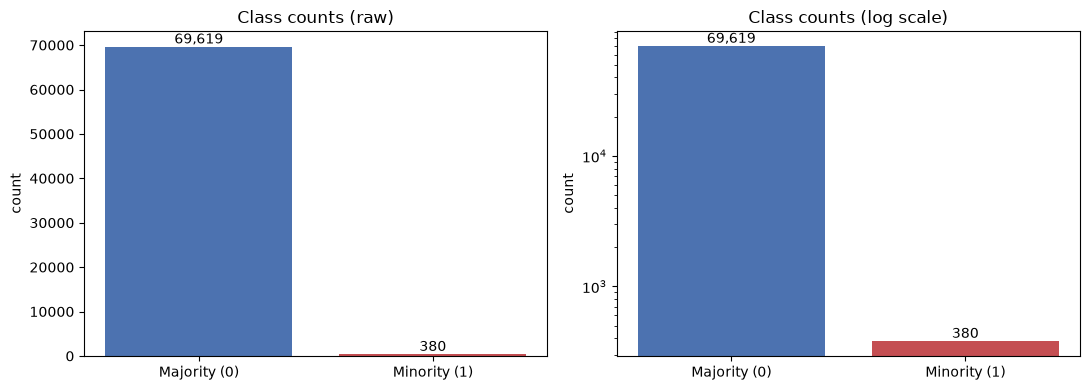

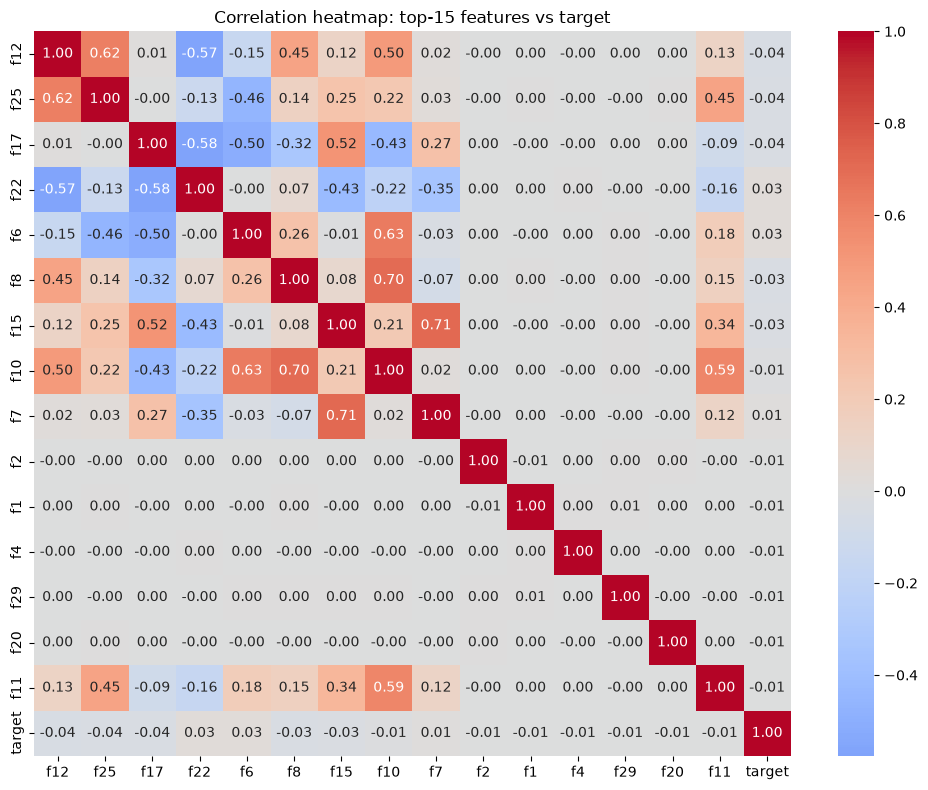

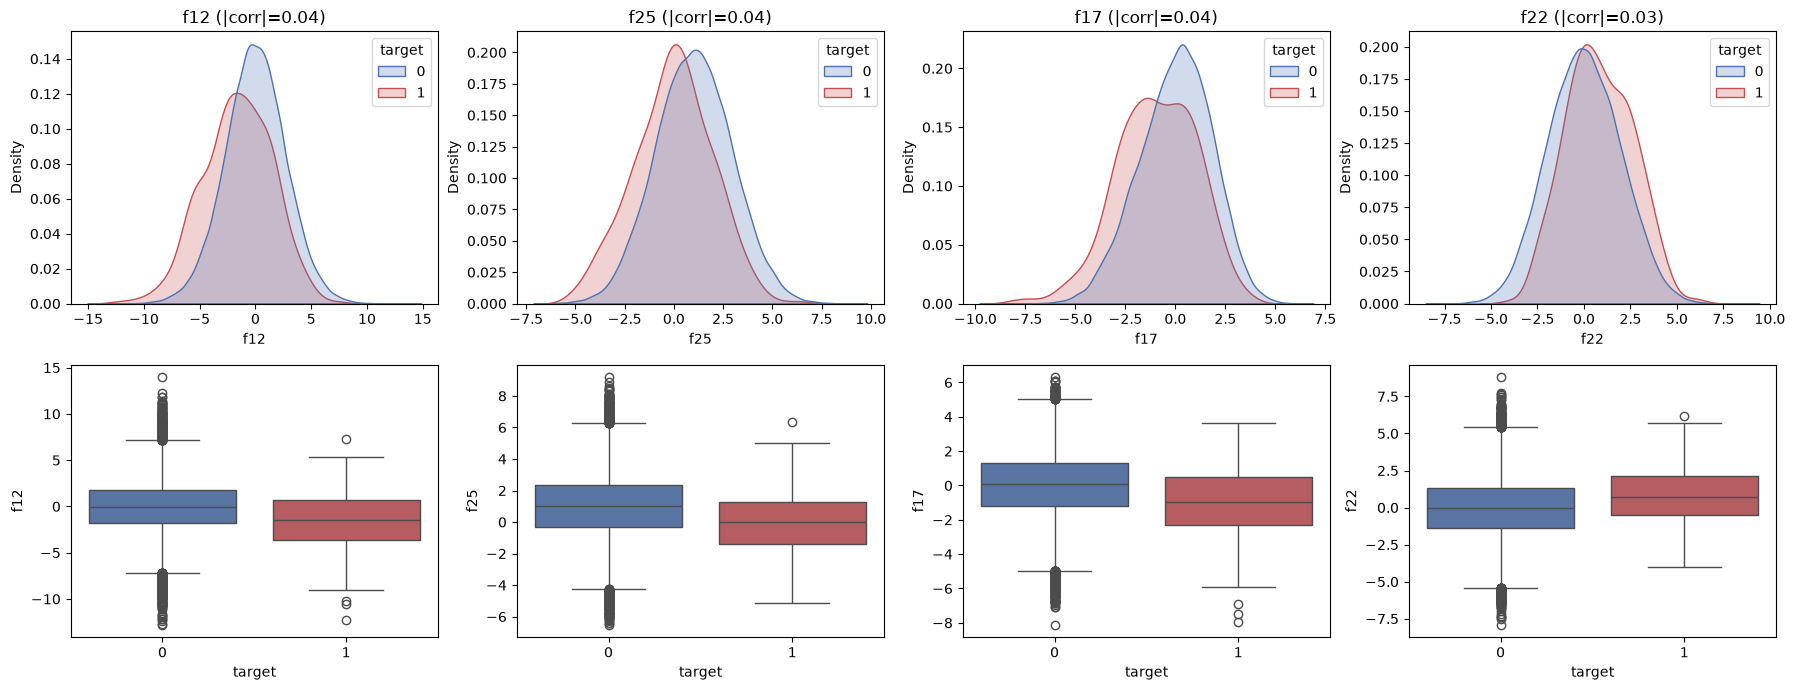

saved 3 plots to outputs\data_plots
[DONE ] EDA plots  (3.3s)


In [9]:
df = load_data(cfg)
X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(df, cfg)
eda_plots(X_tr, y_tr, cfg)

In [10]:
ratio = float((y_tr == 0).sum() / max((y_tr == 1).sum(), 1))   # neg/pos ratio from TRAIN only
print(f"train neg/pos ratio = {ratio:.1f}")
fe, A_tr, A_va, A_te = build_features(X_tr, y_tr, X_va, X_te, cfg)
folds = make_cv_folds(X_tr, y_tr, cfg)
print("leak-free CV folds prepared")

train neg/pos ratio = 183.2

[START] Feature engineering (fit on train only)


features: 30 raw -> 74 engineered
[DONE ] Feature engineering (fit on train only)  (2.6s)


leak-free CV folds prepared


In [11]:
trained = tune_and_train(specs, folds, A_tr, y_tr, ratio, cfg)
specs = [s for s in specs if s.name in trained]


[START] Hyper-parameter tuning + final training

--- XGBoost_GPU: 15 Optuna trials ---


best CV PR-AUC = 0.4820


saved -> outputs\saved_models\xgboost_gpu.json  (50.3s)

--- CatBoost_GPU: 15 Optuna trials ---


best CV PR-AUC = 0.5804


saved -> outputs\saved_models\catboost_gpu.cbm  (271.4s)

--- Resample+XGB_GPU: 6 Optuna trials ---


best CV PR-AUC = 0.4424


saved -> outputs\saved_models\resample_xgb_gpu_pipeline.joblib  (22.3s)
[DONE ] Hyper-parameter tuning + final training  (344.0s)


In [12]:
table, store, best = evaluate(trained, A_va, y_va, A_te, y_te, cfg)
table.round(4)


[START] Evaluation & threshold tuning



TEST-SET RESULTS (threshold tuned on validation)
                  Threshold  Val F2  Val PR-AUC  PR-AUC  ROC-AUC      F1      F2  Precision  Recall     MCC
Model                                                                                                      
XGBoost_GPU          0.1666  0.6250      0.6390  0.5864   0.9182  0.5931  0.5541     0.6719  0.5309  0.5953
CatBoost_GPU         0.4255  0.6667      0.6860  0.6247   0.9365  0.6429  0.5875     0.7627  0.5556  0.6494
Resample+XGB_GPU     0.0875  0.5756      0.5769  0.5163   0.9078  0.4488  0.5134     0.3710  0.5679  0.4554

Best model (by validation PR-AUC): CatBoost_GPU
[DONE ] Evaluation & threshold tuning  (0.2s)


,Threshold,Val F2,Val PR-AUC,PR-AUC,ROC-AUC,F1,F2,Precision,Recall,MCC
Model,,,,,,,,,,
XGBoost_GPU,0.1666,0.6250,0.6390,0.5864,0.9182,0.5931,0.5541,0.6719,0.5309,0.5953
CatBoost_GPU,0.4255,0.6667,0.6860,0.6247,0.9365,0.6429,0.5875,0.7627,0.5556,0.6494
Resample+XGB_GPU,0.0875,0.5756,0.5769,0.5163,0.9078,0.4488,0.5134,0.3710,0.5679,0.4554



[START] Evaluation plots


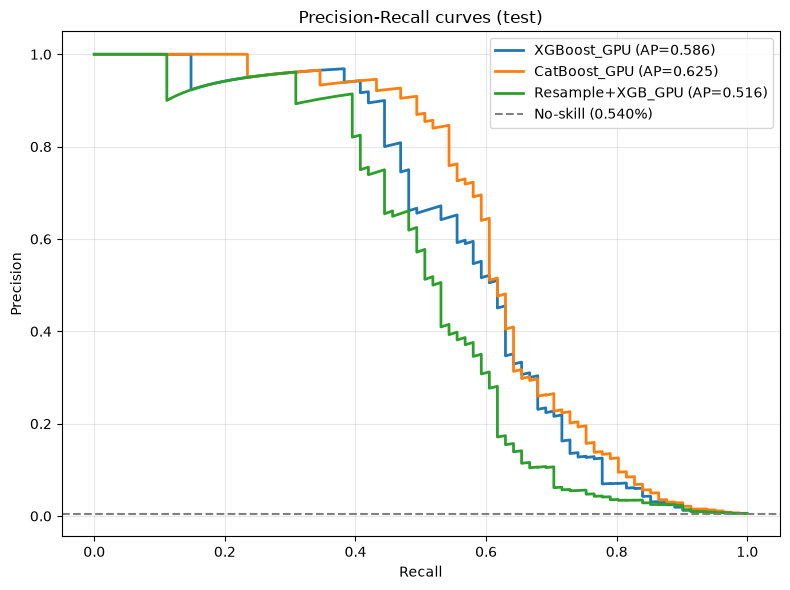

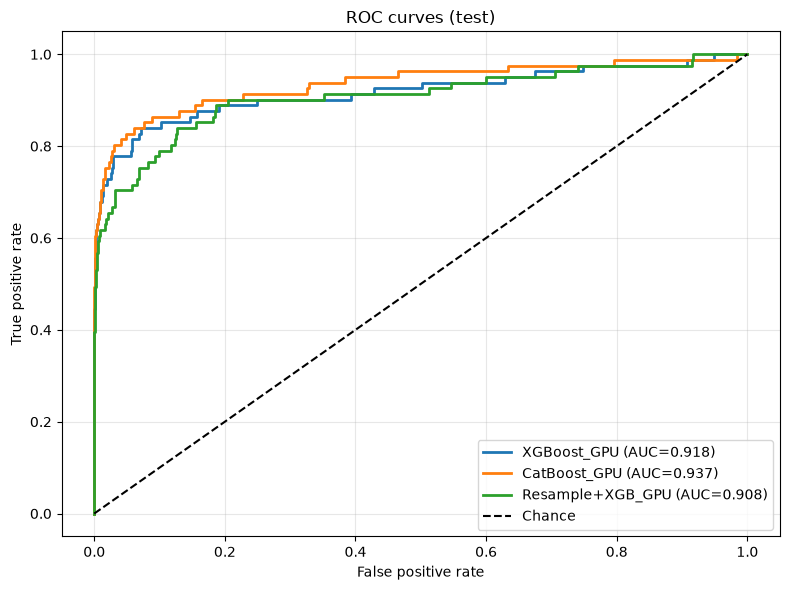

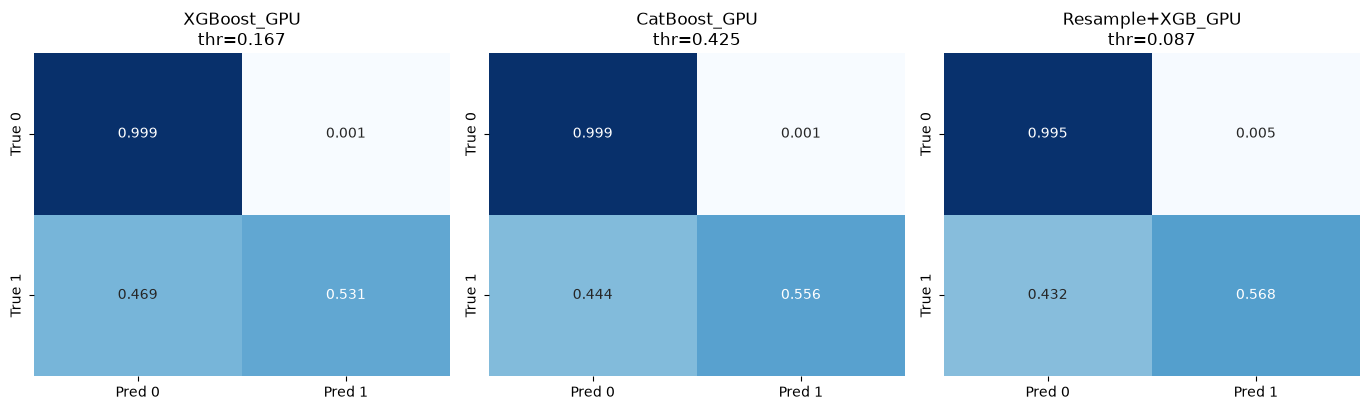

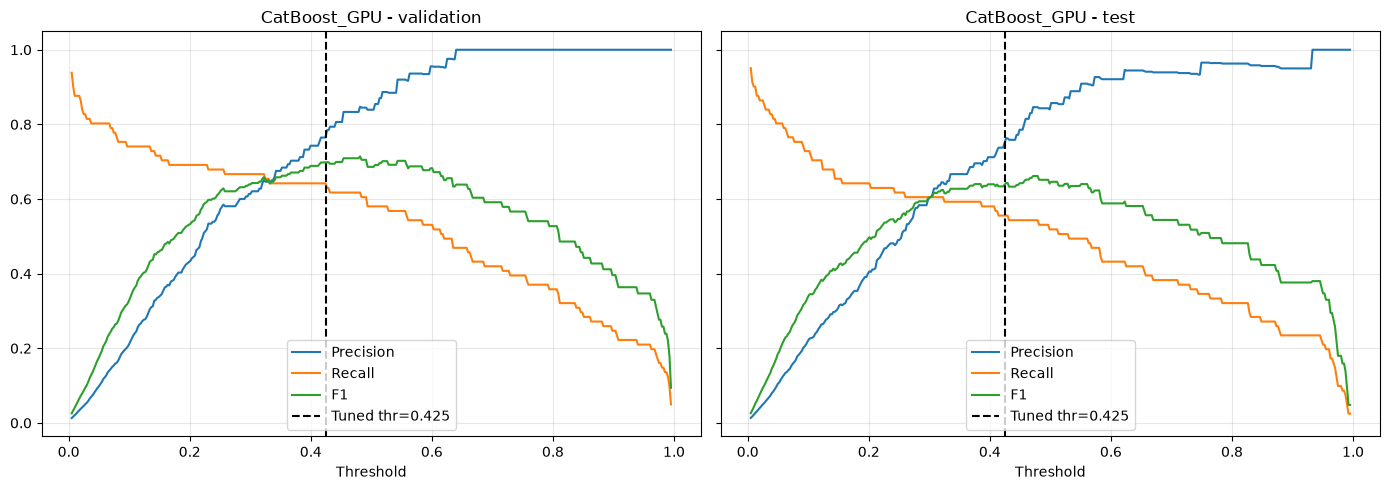

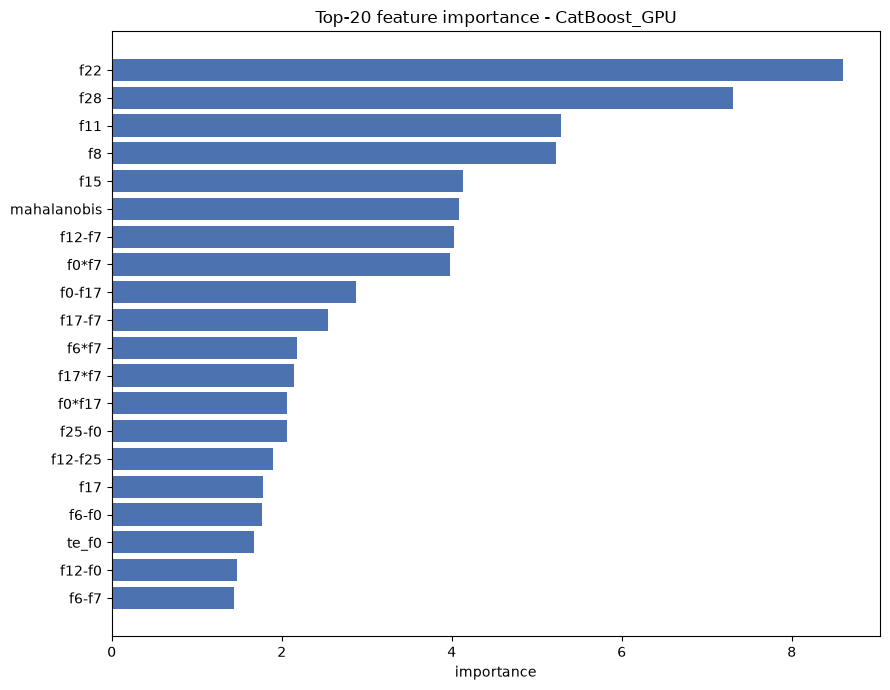

saved 5 plots to outputs\eval_plots
[DONE ] Evaluation plots  (5.0s)
Total runtime: 363.2s | outputs in ./outputs


In [13]:
eval_plots(trained, store, table, best, fe, y_va, y_te, specs, cfg)
print(f"Total runtime: {time.perf_counter() - t_all:.1f}s | outputs in ./{cfg.out_dir}")